# Credit Card Approval Prediction

*We are trying to predict to whom to approve the credit card.*

Credit score cards are a common risk control method in the financial industry. It uses personal information and data submitted by credit card applicants to predict the probability of future defaults and credit card borrowings. The bank is able to decide whether to issue a credit card to the applicant. Credit scores can objectively quantify the magnitude of risk.
 
Generally speaking, credit score cards are based on historical data. Once encountering large economic fluctuations. Past models may lose their original predictive power. Logistic model is a common method for credit scoring.  We will be aso using Boosting, Random Forest, and Support Vector Machines to form the model and make comparision. Then choosing the best model.

Our objective is to  predict if an applicant is 'good' or 'bad' client. This Machine Learning (ML) task is regression since the label (or target) we are trying to predict is numeric, we derived it from classifying the given column.

The example data is provided by Kaggle at [Credit Card Approval Prediction](https://www.kaggle.com/datasets/rikdifos/credit-card-approval-prediction?select=application_record.csv).

#### Load Your Data
Now that we understand what we are trying to do, we need to load our data and describe it, explore it and verify it.

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import *

spark = SparkSession.builder \
    .appName("CreditCardApproval") \
    .master("local[*]") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Spark version:", spark.version)


print(spark)

Spark version: 4.0.1


In [1]:
from pyspark.sql.functions import col, count, when, regexp_extract, stddev, countDistinct
from pyspark.ml.feature import StringIndexer, OneHotEncoder
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler


In [3]:
# Path to our files
file_path1 = "file:///H:/Documents/Bigdata_course/Credit Card Approval/application_record.csv"

app_df = (spark.read
    .option("header", True)      # first row as header
    .csv(file_path1)
    )
app_df.printSchema()
app_df.show(5)



root
 |-- ID: string (nullable = true)
 |-- CODE_GENDER: string (nullable = true)
 |-- FLAG_OWN_CAR: string (nullable = true)
 |-- FLAG_OWN_REALTY: string (nullable = true)
 |-- CNT_CHILDREN: string (nullable = true)
 |-- AMT_INCOME_TOTAL: string (nullable = true)
 |-- NAME_INCOME_TYPE: string (nullable = true)
 |-- NAME_EDUCATION_TYPE: string (nullable = true)
 |-- NAME_FAMILY_STATUS: string (nullable = true)
 |-- NAME_HOUSING_TYPE: string (nullable = true)
 |-- DAYS_BIRTH: string (nullable = true)
 |-- DAYS_EMPLOYED: string (nullable = true)
 |-- FLAG_MOBIL: string (nullable = true)
 |-- FLAG_WORK_PHONE: string (nullable = true)
 |-- FLAG_PHONE: string (nullable = true)
 |-- FLAG_EMAIL: string (nullable = true)
 |-- OCCUPATION_TYPE: string (nullable = true)
 |-- CNT_FAM_MEMBERS: string (nullable = true)

+-------+-----------+------------+---------------+------------+----------------+--------------------+--------------------+--------------------+-----------------+----------+----------

In [4]:
file_path2 = "file:///H:/Documents/Bigdata_course/Credit Card Approval/credit_record.csv"

crd_df = (spark.read
    .option("header", True)      # first row as header
    .csv(file_path2)
    )

crd_df.printSchema()
crd_df.show(5)

root
 |-- ID: string (nullable = true)
 |-- MONTHS_BALANCE: string (nullable = true)
 |-- STATUS: string (nullable = true)

+-------+--------------+------+
|     ID|MONTHS_BALANCE|STATUS|
+-------+--------------+------+
|5001711|             0|     X|
|5001711|            -1|     0|
|5001711|            -2|     0|
|5001711|            -3|     0|
|5001712|             0|     C|
+-------+--------------+------+
only showing top 5 rows


In [5]:
from pyspark.sql.functions import col, when, max as spark_max

# Create a 'label' column: 1 if STATUS >= 3 ever, else 0
crd_df = crd_df.withColumn(
    "bad_status",
    when(col("STATUS").isin(['3','4','5']), 1).otherwise(0)
)

# Aggregate per ID to get final label
label_df = crd_df.groupBy("ID").agg(spark_max("bad_status").alias("label"))

label_df.show(5)


+-------+-----+
|     ID|label|
+-------+-----+
|5001730|    0|
|5001734|    0|
|5001745|    0|
|5001768|    0|
|5001798|    0|
+-------+-----+
only showing top 5 rows


In [6]:
# Join application features with label
data = app_df.join(label_df, on="ID", how="inner")



In [7]:
#looking the schema
data.printSchema()

root
 |-- ID: string (nullable = true)
 |-- CODE_GENDER: string (nullable = true)
 |-- FLAG_OWN_CAR: string (nullable = true)
 |-- FLAG_OWN_REALTY: string (nullable = true)
 |-- CNT_CHILDREN: string (nullable = true)
 |-- AMT_INCOME_TOTAL: string (nullable = true)
 |-- NAME_INCOME_TYPE: string (nullable = true)
 |-- NAME_EDUCATION_TYPE: string (nullable = true)
 |-- NAME_FAMILY_STATUS: string (nullable = true)
 |-- NAME_HOUSING_TYPE: string (nullable = true)
 |-- DAYS_BIRTH: string (nullable = true)
 |-- DAYS_EMPLOYED: string (nullable = true)
 |-- FLAG_MOBIL: string (nullable = true)
 |-- FLAG_WORK_PHONE: string (nullable = true)
 |-- FLAG_PHONE: string (nullable = true)
 |-- FLAG_EMAIL: string (nullable = true)
 |-- OCCUPATION_TYPE: string (nullable = true)
 |-- CNT_FAM_MEMBERS: string (nullable = true)
 |-- label: integer (nullable = true)



### Feature Engineering

In [8]:
# Deriving the value of 'AGE' from 'DAYS_BIRTH' 

data = data.withColumn(
    "AGE_YEARS",
    floor(abs(col("DAYS_BIRTH")) / 365)
)

#Droping the column DAYS_BIRTH

data = data.drop("DAYS_BIRTH")


DAYS_EMPLOYED is the number of days before today the person started working. Two columns can be derived from this column, i.e Employment Duration and Employment Status

In [9]:
# Deriving the value of EMPLOYED_YEARS

data = data.withColumn(
    "EMPLOYED_YEARS",
    when(col("DAYS_EMPLOYED") < 0, abs(col("DAYS_EMPLOYED")) / 365)
    .otherwise(None)
)

data = data.withColumn("EMPLOYED_YEARS", floor(col("EMPLOYED_YEARS")))

# Deriving the value of IS_EMPLOYED

data = data.withColumn(
    "IS_EMPLOYED",
    when(col("DAYS_EMPLOYED") < 0, 1).otherwise(0)
)

# Drop the column DAYS_EMPLOYED

data = data.drop("DAYS_EMPLOYED")


Since, all the features column are in string, we will convert CNT_CHILDREN, AMT_INCOME_TOTAL, AGE_YEARS, EMPLOYED_YEARS, IS_EMPLOYED, CNT_FAM_MEMBERS and others in numeric column.

In [10]:
# List of columns you want to convert
columns_to_cast = {
    "ID": "integer",
    "CNT_CHILDREN": "integer",
    "AMT_INCOME_TOTAL": "double",
    "AGE_YEARS": "integer",
    "EMPLOYED_YEARS": "integer",
    "IS_EMPLOYED": "integer",
    "FLAG_MOBIL": "integer",
    "FLAG_WORK_PHONE": "integer",
    "FLAG_PHONE": "integer",
    "FLAG_EMAIL": "integer",
    "CNT_FAM_MEMBERS": "double"
}

# Cast the columns
for column, dtype in columns_to_cast.items():
    data = data.withColumn(column, col(column).cast(dtype))

# Verify the new schema
data.printSchema()


root
 |-- ID: integer (nullable = true)
 |-- CODE_GENDER: string (nullable = true)
 |-- FLAG_OWN_CAR: string (nullable = true)
 |-- FLAG_OWN_REALTY: string (nullable = true)
 |-- CNT_CHILDREN: integer (nullable = true)
 |-- AMT_INCOME_TOTAL: double (nullable = true)
 |-- NAME_INCOME_TYPE: string (nullable = true)
 |-- NAME_EDUCATION_TYPE: string (nullable = true)
 |-- NAME_FAMILY_STATUS: string (nullable = true)
 |-- NAME_HOUSING_TYPE: string (nullable = true)
 |-- FLAG_MOBIL: integer (nullable = true)
 |-- FLAG_WORK_PHONE: integer (nullable = true)
 |-- FLAG_PHONE: integer (nullable = true)
 |-- FLAG_EMAIL: integer (nullable = true)
 |-- OCCUPATION_TYPE: string (nullable = true)
 |-- CNT_FAM_MEMBERS: double (nullable = true)
 |-- label: integer (nullable = true)
 |-- AGE_YEARS: integer (nullable = true)
 |-- EMPLOYED_YEARS: integer (nullable = true)
 |-- IS_EMPLOYED: integer (nullable = false)



In [11]:
# List all numeric columns (integer or double)
numeric_cols = [c for c, t in data.dtypes if t in ("int", "double")]

print("Numeric columns:")
print(numeric_cols)


Numeric columns:
['ID', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'label', 'AGE_YEARS', 'EMPLOYED_YEARS', 'IS_EMPLOYED']


## DATA PREPROCESSING

In [12]:
# Identify categorical columns
categorical_cols = [c for c, t in data.dtypes if t == "string"]

print("Categorical columns BEFORE special character check:")
print(categorical_cols)


Categorical columns BEFORE special character check:
['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']


#### Identifying ID like column

In [13]:
from pyspark.sql.functions import approx_count_distinct

id_like_cols = [
    c for c in data.columns
    if c != "ID" and
       data.select(approx_count_distinct(c)).collect()[0][0] / data.count() > 0.95
]

print("ID-like columns (excluding ID):", id_like_cols)

ID-like columns (excluding ID): []


#### Handling special charaters

In [14]:
#Find columns containing special characters

special_char_cols = []

for c in categorical_cols:
    if data.filter(col(c).rlike("[^a-zA-Z0-9_ ]")).count() > 0:
        special_char_cols.append(c)

print("Columns with special characters:")
print(special_char_cols)


Columns with special characters:
['NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']


#### Looking for columns with More than 50% Missing Values

In [15]:
total_rows = data.count() 
 
missing_cols = [] 
 
for c in data.columns: 
    missing_count = data.filter(col(c).isNull()).count() 
    if missing_count / total_rows > 0.5: 
        missing_cols.append(c) 
 
print("Columns with >50% missing BEFORE drop:") 
print(missing_cols) 


Columns with >50% missing BEFORE drop:
[]


#### Low Variance Numeric Columns

In [16]:
numeric_cols = [c for c, t in data.dtypes if t in ["int", "double"] and c != "label"] 
 
print("Numeric columns BEFORE variance check:") 
print(numeric_cols) 
 

#Looking for low variance 

low_variance_cols = [] 
 
for c in numeric_cols: 
    var = data.select(stddev(col(c))).first()[0] 
    if var is not None and var < 0.01: 
        low_variance_cols.append(c) 
 
print("Low variance numeric columns:") 
print(low_variance_cols) 
 

Numeric columns BEFORE variance check:
['ID', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'AGE_YEARS', 'EMPLOYED_YEARS', 'IS_EMPLOYED']
Low variance numeric columns:
['FLAG_MOBIL']


#### Handling High Cardinality Categorical Columns

In [17]:
categorical_cols = [c for c, t in data.dtypes if t == "string"] 
 
print("Categorical columns BEFORE cardinality check:") 
print(categorical_cols) 
 

#Detect high cardinality (threshold = 50) 

high_cardinality_cols = [] 
 
for c in categorical_cols: 
    distinct_count = data.select(countDistinct(col(c))).first()[0] 
    if distinct_count > 50: 
        high_cardinality_cols.append(c) 
 
print("\nHigh cardinality categorical columns:") 
print(high_cardinality_cols)

Categorical columns BEFORE cardinality check:
['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']

High cardinality categorical columns:
[]


#### Highly Correlated Columns

In [18]:
from pyspark.sql.functions import col

# List numeric columns
numeric_cols = [c for c, t in data.dtypes if t in ["int", "double"] and c not in ["FLAG_MOBIL", "label"]]

threshold = 0.95
high_corr_pairs = []

# Loop over all pairs of numeric columns
for i in range(len(numeric_cols)):
    for j in range(i+1, len(numeric_cols)):
        c1 = numeric_cols[i]
        c2 = numeric_cols[j]
        # PySpark column-wise correlation returns a float
        corr_val = data.stat.corr(c1, c2)
        # Use Python built-in abs() on the float
        if __builtins__.abs(corr_val) > threshold:
            high_corr_pairs.append((c1, c2, corr_val))

# Display results
print("Highly correlated column pairs (|corr| > 0.95):")
for pair in high_corr_pairs:
    print(pair)


Highly correlated column pairs (|corr| > 0.95):


In [19]:
#High correlation list
high_corr_cols = [pair[1] for pair in high_corr_pairs]  # second column in each pair
print(high_corr_cols)


[]


### Concatenating all the Irrelevant column

In [20]:
# Example column lists (some could be None)
id_like_cols = id_like_cols if id_like_cols is not None else []
special_char_cols = special_char_cols if special_char_cols is not None else []
missing_cols = missing_cols if missing_cols is not None else []
low_variance_cols = low_variance_cols if low_variance_cols is not None else []
high_cardinality_cols = high_cardinality_cols if high_cardinality_cols is not None else []
high_corr_cols = high_corr_cols if high_corr_cols is not None else []

# Ensure all are lists (sometimes they could be tuples or other iterables)
id_like_cols = list(id_like_cols)
special_char_cols = list(special_char_cols)
missing_cols = list(missing_cols)
low_variance_cols = list(low_variance_cols)
high_cardinality_cols = list(high_cardinality_cols)
high_corr_cols = list(high_corr_cols)

# Concatenate all lists
irrelevant_cols = (
    id_like_cols +
    special_char_cols +
    missing_cols +
    low_variance_cols +
    high_cardinality_cols +
    high_corr_cols
)

# Display final list of columns to drop/review
print("\nIdentified irrelevant columns to review:")
print(irrelevant_cols)



Identified irrelevant columns to review:
['NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'FLAG_MOBIL']


In [21]:
# Dropping the irrelant columns and also adding some manually

# Add 'AMT_INCOME_TOTAL' to the list
irrelevant_cols.append("NAME_INCOME_TYPE")

# Drop all irrelevant columns from the DataFrame
data_clean = data.drop(*irrelevant_cols)

# Show the first 5 rows
data_clean.show(5)


+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|     ID|CODE_GENDER|FLAG_OWN_CAR|FLAG_OWN_REALTY|CNT_CHILDREN|AMT_INCOME_TOTAL|FLAG_WORK_PHONE|FLAG_PHONE|FLAG_EMAIL|CNT_FAM_MEMBERS|label|AGE_YEARS|EMPLOYED_YEARS|IS_EMPLOYED|
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|5008804|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0|    0|       32|            12|          1|
|5008805|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0|    0|       32|            12|          1|
|5008806|          M|           Y|              Y|           0|        112500.0|              0|         0|   

In [22]:
# to filter the value of label=1
label_1_df = data_clean.filter(data_clean["label"] == 1)

# Show the first 10 rows (or any number you want)
label_1_df.show(10)


+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|     ID|CODE_GENDER|FLAG_OWN_CAR|FLAG_OWN_REALTY|CNT_CHILDREN|AMT_INCOME_TOTAL|FLAG_WORK_PHONE|FLAG_PHONE|FLAG_EMAIL|CNT_FAM_MEMBERS|label|AGE_YEARS|EMPLOYED_YEARS|IS_EMPLOYED|
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|5009628|          F|           N|              N|           0|        238500.0|              1|         0|         0|            2.0|    1|       52|             9|          1|
|5009746|          F|           Y|              N|           0|        315000.0|              1|         1|         0|            2.0|    1|       37|             1|          1|
|5010061|          F|           N|              Y|           0|        112500.0|              0|         0|   

### Handling the Duplicate Value

In [23]:
# Show DataFrame BEFORE dropping duplicates
print("DataFrame BEFORE dropping duplicates:")
print(f"Total rows: {data_clean.count()}")
data_clean.show(5)  # Preview top 5 rows

# Count duplicated rows

from pyspark.sql import functions as F

duplicated_rows_count = (
    data_clean.groupBy(data_clean.columns)
    .count()
    .filter(F.col("count") > 1)
    .agg(F.sum("count") - F.count("*"))  # total duplicates = sum(counts >1) - unique rows
    .collect()[0][0]
)

print(f"\nNumber of duplicated rows: {duplicated_rows_count}")



DataFrame BEFORE dropping duplicates:
Total rows: 36457
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|     ID|CODE_GENDER|FLAG_OWN_CAR|FLAG_OWN_REALTY|CNT_CHILDREN|AMT_INCOME_TOTAL|FLAG_WORK_PHONE|FLAG_PHONE|FLAG_EMAIL|CNT_FAM_MEMBERS|label|AGE_YEARS|EMPLOYED_YEARS|IS_EMPLOYED|
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|5008804|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0|    0|       32|            12|          1|
|5008805|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0|    0|       32|            12|          1|
|5008806|          M|           Y|              Y|    

#### Handling Outliers

In [24]:
#selecting numeric columns

numeric_cols = [
    c for c, t in data_clean.dtypes
    if t in ["int", "double"] and c != "label"
]

print("Numeric columns for outlier detection:")
print(numeric_cols)

#IQR bounds for each numeric columns

# Dictionary to store bounds
iqr_bounds = {}

for c in numeric_cols:
    q1, q3 = data_clean.approxQuantile(c, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    lower_bound = q1 - 3 * iqr
    upper_bound = q3 + 3 * iqr

    iqr_bounds[c] = (lower_bound, upper_bound)

    print(f"{c}: lower={lower_bound}, upper={upper_bound}")




Numeric columns for outlier detection:
['ID', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'AGE_YEARS', 'EMPLOYED_YEARS', 'IS_EMPLOYED']
ID: lower=4824886.0, upper=5331378.0
CNT_CHILDREN: lower=-3.0, upper=4.0
AMT_INCOME_TOTAL: lower=-189000.0, upper=535500.0
FLAG_WORK_PHONE: lower=0.0, upper=0.0
FLAG_PHONE: lower=-3.0, upper=4.0
FLAG_EMAIL: lower=0.0, upper=0.0
CNT_FAM_MEMBERS: lower=-1.0, upper=6.0
AGE_YEARS: lower=-24.0, upper=109.0
EMPLOYED_YEARS: lower=-19.0, upper=30.0
IS_EMPLOYED: lower=1.0, upper=1.0


In [25]:
#identify the outliers

outlier_condition = None

for c, (low, high) in iqr_bounds.items():
    condition = (col(c) < low) | (col(c) > high)
    outlier_condition = condition if outlier_condition is None else (outlier_condition | condition)

outliers_df = data_clean.filter(outlier_condition)

print("Outliers preview:")
outliers_df.show(5)

print("Number of outlier rows:", outliers_df.count())



Outliers preview:
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|     ID|CODE_GENDER|FLAG_OWN_CAR|FLAG_OWN_REALTY|CNT_CHILDREN|AMT_INCOME_TOTAL|FLAG_WORK_PHONE|FLAG_PHONE|FLAG_EMAIL|CNT_FAM_MEMBERS|label|AGE_YEARS|EMPLOYED_YEARS|IS_EMPLOYED|
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|5008804|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0|    0|       32|            12|          1|
|5008805|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0|    0|       32|            12|          1|
|5008808|          F|           N|              Y|           0|        270000.0|            

Here, the number of outliers is around 47% of the total number of rows. And by looking at the nature of columns, some columns like days_birth(negative value), days_employed(highly skewed) and some may have low variance. So, we are not dropping the outlier rows. So, we will include those columns that are suitable.

In [26]:
# Selecting the numeric columns

from pyspark.sql.functions import col

outlier_cols = [
    "AMT_INCOME_TOTAL",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "AGE_YEARS",
    "EMPLOYED_YEARS"   # optional but acceptable
]

print("Columns used for outlier detection:")
print(outlier_cols)


#Identifying outliers

outlier_condition = None

for c, (low, high) in iqr_bounds.items():
    condition = (col(c) < low) | (col(c) > high)
    outlier_condition = condition if outlier_condition is None else (outlier_condition | condition)

outliers_df = data_clean.filter(outlier_condition)

print("Number of outlier rows:", outliers_df.count())
outliers_df.show(5)


Columns used for outlier detection:
['AMT_INCOME_TOTAL', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'AGE_YEARS', 'EMPLOYED_YEARS']
Number of outlier rows: 17285
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|     ID|CODE_GENDER|FLAG_OWN_CAR|FLAG_OWN_REALTY|CNT_CHILDREN|AMT_INCOME_TOTAL|FLAG_WORK_PHONE|FLAG_PHONE|FLAG_EMAIL|CNT_FAM_MEMBERS|label|AGE_YEARS|EMPLOYED_YEARS|IS_EMPLOYED|
+-------+-----------+------------+---------------+------------+----------------+---------------+----------+----------+---------------+-----+---------+--------------+-----------+
|5008804|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0|    0|       32|            12|          1|
|5008805|          M|           Y|              Y|           0|        427500.0|              1|         0|         0|            2.0| 

In [27]:
# Capping replaces the values bounds with lower or upper limit

for c, (low, high) in iqr_bounds.items():
    data2 = data_clean.withColumn(
        c,
        when(col(c) < low, low)
        .when(col(c) > high, high)
        .otherwise(col(c))
    )

# Log-transform skewed variables

data2 = data2.withColumn("AMT_INCOME_TOTAL_LOG", log1p(col("AMT_INCOME_TOTAL")))


Since, CNT_CHILDREN and CNT_FAM_MEMBERS are small integer, EMPLOYED_YEARS has negative values and AGE_YEARS is distributed roughly normal after derivation, LOG is applied to only one column.

### Imputate Missing Values

In [28]:
from pyspark.ml.feature import Imputer

def impute_missing_values(df, label_col="label"):
    """
    Imputes missing values:
    - Numeric columns: median
    - Categorical columns: mode
    """
    # Identify numeric and categorical columns
    numeric_cols = [
        c for c, t in df.dtypes
        if t in ["int", "double"] and c != label_col
    ]

    categorical_cols = [
        c for c, t in df.dtypes
        if t == "string"
    ]

    # ---- Numeric imputation (median) ----
    if numeric_cols:
        imputer = Imputer(
            inputCols=numeric_cols,
            outputCols=numeric_cols,
            strategy="median"
        )
        df = imputer.fit(df).transform(df)

    # ---- Categorical imputation (mode) ----
    for c in categorical_cols:
        mode = (
            df.groupBy(c)
            .count()
            .orderBy("count", ascending=False)
            .first()
        )
        if mode:
            df = df.fillna({c: mode[c]})

    return df


In [29]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, Imputer
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml import Pipeline
from pyspark.sql.functions import col
from pyspark.ml.classification import LinearSVC, NaiveBayes


store ={} #to store train_df

def run_classification_pyspark(df, target_column, categorical_cols=None, onehot_encode_cols=None, scale_cols=None, model_name=None, test_size=0.2, seed=42, store=None):
    """
    PySpark classification pipeline:
    - Missing value imputation
    - Categorical encoding
    - Scaling numeric features
    - Model training and evaluation
    - Excludes 'ID' and 'label' from features automatically
    """

    # Step 0: Impute missing numeric values
    
    df = impute_missing_values(df, label_col=target_column)

  
    # Step 1: Split into train/test
   
    train_df, test_df = df.randomSplit([1 - test_size, test_size], seed=seed)

    # Separate majority and minority classes
    minority = train_df.filter(col("label") == 1)
    majority = train_df.filter(col("label") == 0)

    # Calculate oversampling fraction
    oversample_fraction = majority.count() / minority.count()

    # Oversample minority with replacement
    minority_oversampled = minority.sample(withReplacement=True, fraction=oversample_fraction, seed=42)

    # Combine with majority
    train_df = majority.union(minority_oversampled)

    # Shuffle rows
    train_df = train_df.orderBy(F.rand())


    # Step 2: Handle categorical columns
    
    indexers = []
    encoders = []
    input_cols = []

    if categorical_cols:
        for c in categorical_cols:
            indexer = StringIndexer(inputCol=c, outputCol=f"{c}_indexed", handleInvalid="keep")
            indexers.append(indexer)
            input_cols.append(f"{c}_indexed")

    if onehot_encode_cols:
        for c in onehot_encode_cols:
            encoder = OneHotEncoder(inputCol=f"{c}_indexed", outputCol=f"{c}_ohe", dropLast=True)
            encoders.append(encoder)
            input_cols.append(f"{c}_ohe")

   
    # Step 3: Include numeric columns excluding ID and target
  
    numeric_cols = [c for c, t in df.dtypes if t in ["int", "double"] and c not in [target_column, "ID"]]
    input_cols += numeric_cols

    
    # Step 4: Assemble features vector
   
    assembler = VectorAssembler(inputCols=input_cols, outputCol="features")

   
    # Step 5: Scale numeric features (optional)
   
    if scale_cols:
        scaler = StandardScaler(inputCol="features", outputCol="scaled_features", withMean=True, withStd=True)
        features_col = "scaled_features"
    else:
        features_col = "features"

   
    # Step 6: Initialize model
    
    if model_name == "LR":
        model = LogisticRegression(featuresCol=features_col, labelCol=target_column)
    elif model_name == "DT":
        model = DecisionTreeClassifier(featuresCol=features_col, labelCol=target_column)
    elif model_name == "RF":
        model = RandomForestClassifier(featuresCol=features_col, labelCol=target_column)
    elif model_name == "GB":
        model = GBTClassifier(featuresCol=features_col, labelCol=target_column)
    elif model_name == "SVM":
        model = LinearSVC(featuresCol=features_col, labelCol=target_column)       
    elif model_name == "NB":
        features_col = "features"  # use raw features
        model = NaiveBayes(featuresCol=features_col, labelCol=target_column) 
    else:
        raise ValueError("Invalid model_name. Choose 'LR', 'DT', 'RF', 'SVM', 'NB' or 'GB'")

    
    # Step 7: Build pipeline
  
    stages = indexers + encoders + [assembler]
    if scale_cols:
        stages.append(scaler)
    stages.append(model)

    pipeline = Pipeline(stages=stages)

    # Step 8: Fit pipeline
    
    pipeline_model = pipeline.fit(train_df)
    predictions = pipeline_model.transform(test_df)

   
    # Step 9: Evaluate
    
    evaluator_acc = MulticlassClassificationEvaluator(labelCol=target_column, metricName="accuracy")
    evaluator_precision = MulticlassClassificationEvaluator(labelCol=target_column, metricName="weightedPrecision")
    evaluator_recall = MulticlassClassificationEvaluator(labelCol=target_column, metricName="weightedRecall")
    evaluator_f1 = MulticlassClassificationEvaluator(labelCol=target_column, metricName="f1")
    evaluator_roc = BinaryClassificationEvaluator(labelCol=target_column, metricName="areaUnderROC")

    metrics = {
        "Accuracy": evaluator_acc.evaluate(predictions),
        "Precision": evaluator_precision.evaluate(predictions),
        "Recall": evaluator_recall.evaluate(predictions),
        "F1-score": evaluator_f1.evaluate(predictions),
        "ROC-AUC": evaluator_roc.evaluate(predictions)
    }

    print(f"\n{model_name} Metrics:")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")

    if store is not None:
        store['train_df'] = train_df

    return metrics, pipeline_model, predictions


### Analyse columns to normalize and encode

In [30]:
from pyspark.sql import DataFrame
from pyspark.sql.types import StringType, NumericType

def analyze_encoding_strategy_pyspark(df: DataFrame, target=None):
    """
    Analyze columns for encoding strategy in PySpark DataFrame.
    - Label encode columns with 2 unique values
    - One-hot encode categorical columns with <=10 unique values
    - Normalize numeric columns with >50 unique values
    - Print high-cardinality categorical columns (>10 unique values)
    """
    
    normalize_cols = []
    label_encode_cols = []
    one_hot_encode_cols = []
    
    total_rows = df.count()
    
    for col_name, dtype in df.dtypes:
        if col_name == target:
            continue  # skip target column
        
        # Count distinct values
        unique_vals = df.select(col_name).distinct().count()
        
        # Skip ID-like columns
        if unique_vals == total_rows:
            continue
        
        # Numeric columns
        if dtype in ["int", "double"]:
            if unique_vals > 50:
                normalize_cols.append(col_name)
        
        # Categorical columns
        else:
            if unique_vals == 2:
                label_encode_cols.append(col_name)
            elif unique_vals <= 10:
                one_hot_encode_cols.append(col_name)
            else:
                print(f" High-cardinality column: {col_name} ({unique_vals} unique values)")
    
    return normalize_cols, label_encode_cols, one_hot_encode_cols

# ------------------------
# Example usage
# ------------------------
target_col = "label"
norm_cols, label_cols, onehot_cols = analyze_encoding_strategy_pyspark(data2, target=target_col)

print("Normalize:", norm_cols)
print("Label Encode:", label_cols)
print("One-Hot Encode:", onehot_cols)


Normalize: ['AMT_INCOME_TOTAL', 'AMT_INCOME_TOTAL_LOG']
Label Encode: ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
One-Hot Encode: []


In [31]:
# Specify all paramters: the columns for label encoding, one-hot encoding, and scaling
label_encode_cols = label_cols
onehot_encode_cols = onehot_cols

# Specify numerical columns columns for scaling 
scale_cols =  norm_cols

# Specify the target column name
target_column_name = 'label'

# Specify the number of rows for the model
num_rows = data2.count()


In [32]:
data2.printSchema()

root
 |-- ID: integer (nullable = true)
 |-- CODE_GENDER: string (nullable = true)
 |-- FLAG_OWN_CAR: string (nullable = true)
 |-- FLAG_OWN_REALTY: string (nullable = true)
 |-- CNT_CHILDREN: integer (nullable = true)
 |-- AMT_INCOME_TOTAL: double (nullable = true)
 |-- FLAG_WORK_PHONE: integer (nullable = true)
 |-- FLAG_PHONE: integer (nullable = true)
 |-- FLAG_EMAIL: integer (nullable = true)
 |-- CNT_FAM_MEMBERS: double (nullable = true)
 |-- label: integer (nullable = true)
 |-- AGE_YEARS: integer (nullable = true)
 |-- EMPLOYED_YEARS: integer (nullable = true)
 |-- IS_EMPLOYED: double (nullable = false)
 |-- AMT_INCOME_TOTAL_LOG: double (nullable = true)



In [33]:
# Choose right scaler dynamically depends on the distribution of your data
import pyspark.sql.functions as F
import numpy as np

def suggest_scaler_pyspark(df, numeric_cols):
    skewness_scores = []
    outlier_ratios = []

    total_count = df.count()

    for col in numeric_cols:
        # Compute skewness
        skewness_val = df.select(F.skewness(F.col(col))).collect()[0][0] or 0
        skewness_scores.append(__builtins__.abs(skewness_val))

        # Compute IQR using approxQuantile
        q75, q25 = df.approxQuantile(col, [0.75, 0.25], 0.01)
        iqr = q75 - q25

        # Compute median
        median_val = df.approxQuantile(col, [0.5], 0.01)[0]

        # Count outliers: abs(value - median) > 1.5*IQR
        outlier_count = df.filter(F.abs(F.col(col) - median_val) > 3 * iqr).count()
        outlier_ratio = outlier_count / total_count
        outlier_ratios.append(outlier_ratio)

    avg_skew = np.mean(skewness_scores)
    avg_outliers = np.mean(outlier_ratios)

    print(f"Avg Skewness: {avg_skew:.2f}")
    print(f"Avg Outlier Ratio: {avg_outliers:.2f}")

    if avg_outliers > 0.15:
        return "robust"
    elif avg_skew > 1:
        return "minmax"
    else:
        return "standard"


# Example usage

numeric_cols = [c for c, t in data2.dtypes if t in ["int", "double", "float"] and c != "ID"]
scaler_name = suggest_scaler_pyspark(data2, numeric_cols)
print(f"Suggested Scaler for all features: {scaler_name}")


Avg Skewness: 2.23
Avg Outlier Ratio: 0.03
Suggested Scaler for all features: minmax


The above result shows that the dataset has high skewness and only 3% of the data is outliers which is low.

In [34]:
from pyspark.sql.functions import col

data2.groupBy(col("label")).count().orderBy("label").show()


+-----+-----+
|label|count|
+-----+-----+
|    0|36155|
|    1|  302|
+-----+-----+



### Oversampling the minority

In [35]:
data5 = data2

In [36]:
from pyspark.sql import functions as F

# Separate majority and minority classes
minority1 = data5.filter(col("label") == 1)
majority1 = data5.filter(col("label") == 0)

# Calculate oversampling fraction
oversample_fraction = majority1.count() / minority1.count()

# Oversample minority with replacement
minority_oversampled = minority1.sample(withReplacement=True, fraction=oversample_fraction, seed=42)

# Combine with majority
balanced_df3 = majority1.union(minority_oversampled)

# Shuffle rows
balanced_df3 = balanced_df3.orderBy(F.rand())

# Check counts
balanced_df3.groupBy("label").count().show()


+-----+-----+
|label|count|
+-----+-----+
|    0|36155|
|    1|36246|
+-----+-----+



In [37]:
# Run Logistic Regression in PySpark and print metrics
lr_metrics, lr_pipeline_model, lr_predictions = run_classification_pyspark(
    data2,
    target_column=target_column_name,
    categorical_cols=label_encode_cols + onehot_encode_cols,
    onehot_encode_cols=onehot_encode_cols,
    scale_cols=scale_cols,
    model_name="LR",
    store=store
)
# Check counts
store['train_df'].groupBy("label").count().show()


LR Metrics:
Accuracy: 0.5646
Precision: 0.9854
Recall: 0.5646
F1-score: 0.7148
ROC-AUC: 0.5692
+-----+-----+
|label|count|
+-----+-----+
|    0|28966|
|    1|29185|
+-----+-----+



In [38]:
# Decision Tree
dt_metrics, dt_model, dt_preds = run_classification_pyspark(
    data2, target_column_name,
    label_encode_cols + onehot_encode_cols,
    onehot_encode_cols,
    scale_cols,
    model_name="DT"
)


DT Metrics:
Accuracy: 0.8450
Precision: 0.9853
Recall: 0.8450
F1-score: 0.9088
ROC-AUC: 0.5235


In [40]:
# Random Forest
rf_metrics, rf_model, rf_preds = run_classification_pyspark(
    data2, target_column_name,
    label_encode_cols + onehot_encode_cols,
    onehot_encode_cols,
    scale_cols,
    model_name="RF"
)


RF Metrics:
Accuracy: 0.7781
Precision: 0.9856
Recall: 0.7781
F1-score: 0.8681
ROC-AUC: 0.6384


In [41]:
# Gradient Boosting
gb_metrics, gb_model, gb_preds = run_classification_pyspark(
    data2, target_column_name,
    label_encode_cols + onehot_encode_cols,
    onehot_encode_cols,
    scale_cols,
    model_name="GB"
)


GB Metrics:
Accuracy: 0.8163
Precision: 0.9881
Recall: 0.8163
F1-score: 0.8917
ROC-AUC: 0.7091


In [42]:
# Support Vector Machine
svm_metrics, svm_model, svm_preds = run_classification_pyspark(
    data2, target_column_name,
    label_encode_cols + onehot_encode_cols,
    onehot_encode_cols,
    scale_cols,
    model_name="SVM"
)


SVM Metrics:
Accuracy: 0.5210
Precision: 0.9854
Recall: 0.5210
F1-score: 0.6780
ROC-AUC: 0.5750


In [43]:
# Naive Bayes
nb_metrics, nb_model, nb_preds = run_classification_pyspark(
    data2, target_column_name,
    label_encode_cols + onehot_encode_cols,
    onehot_encode_cols,
    scale_cols,
    model_name="NB"
)


NB Metrics:
Accuracy: 0.5371
Precision: 0.9843
Recall: 0.5371
F1-score: 0.6921
ROC-AUC: 0.5185


#### Ploting the graph to make comparision in metrices


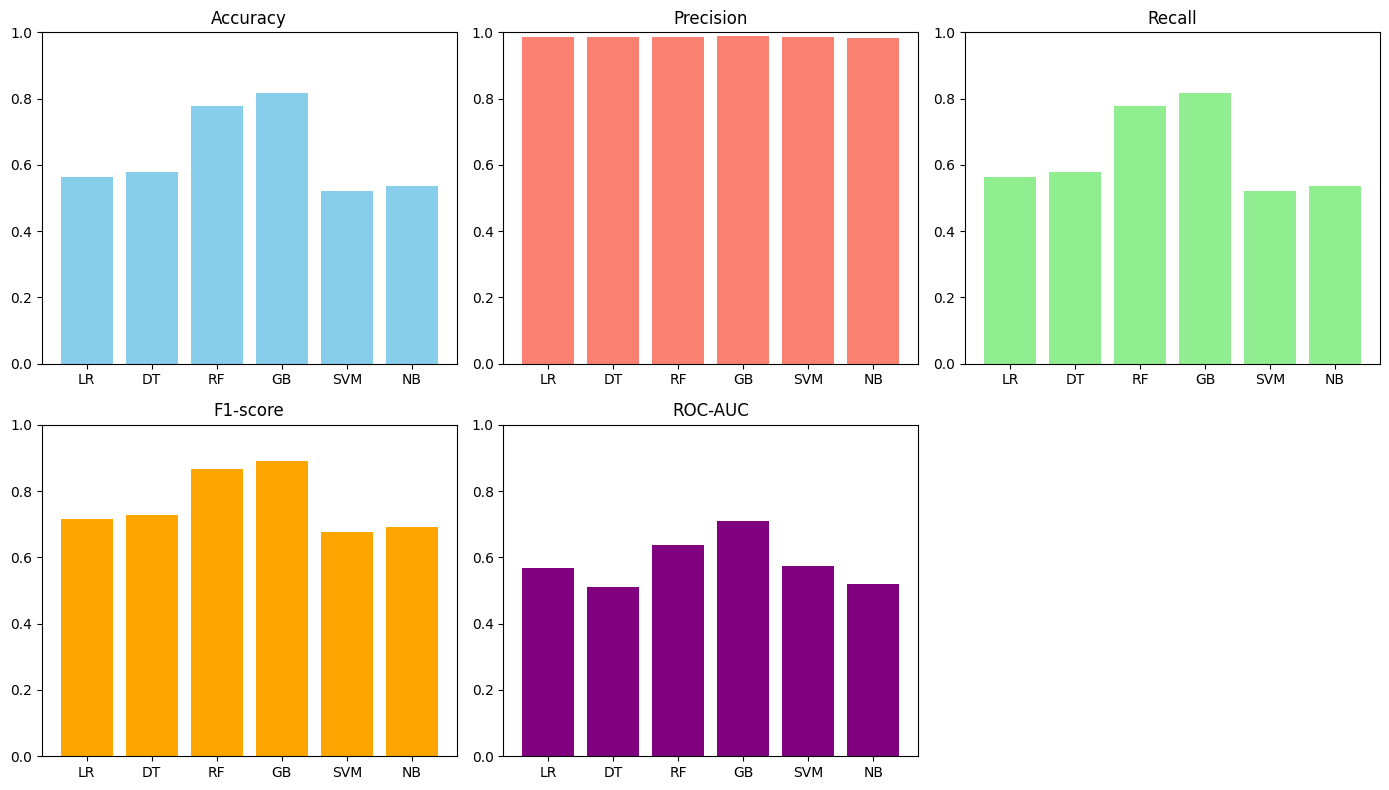

In [44]:
import matplotlib.pyplot as plt

# Assume you have already run models in PySpark and got metrics dictionaries
# For example:
# lr_metrics, dt_metrics, rf_metrics, gb_metrics, svm_metrics, nb_metrics

model_names = ['LR', 'DT', 'RF', 'GB', 'SVM', 'NB']

metrics_list = [
    lr_metrics,  # Output dict from run_classification_pyspark for LR
    dt_metrics,  # Decision Tree
    rf_metrics,  # Random Forest
    gb_metrics,  # Gradient Boosting
    svm_metrics, # SVM
    nb_metrics   # Naive Bayes
]

# Extract each metric for plotting
accuracy = [m['Accuracy'] for m in metrics_list]
precision = [m['Precision'] for m in metrics_list]
recall = [m['Recall'] for m in metrics_list]
f1 = [m['F1-score'] for m in metrics_list]
roc_auc = [m['ROC-AUC'] if m['ROC-AUC'] is not None else 0 for m in metrics_list]  # Replace None with 0

# Plot
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.bar(model_names, accuracy, color='skyblue')
plt.title('Accuracy')
plt.ylim(0, 1)

plt.subplot(2, 3, 2)
plt.bar(model_names, precision, color='salmon')
plt.title('Precision')
plt.ylim(0, 1)

plt.subplot(2, 3, 3)
plt.bar(model_names, recall, color='lightgreen')
plt.title('Recall')
plt.ylim(0, 1)

plt.subplot(2, 3, 4)
plt.bar(model_names, f1, color='orange')
plt.title('F1-score')
plt.ylim(0, 1)

plt.subplot(2, 3, 5)
plt.bar(model_names, roc_auc, color='purple')
plt.title('ROC-AUC')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


From the above fig, it can be observed that Gradient Boosting performance is the best among other metrics before optimization.

#### Grid Search CV

In [45]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder


def run_classification_pyspark_cv(df, target_column, categorical_cols=None, onehot_encode_cols=None,
                                  scale_cols=None, model_name=None, test_size=0.2, seed=42,
                                  model_params=None, n_folds=5):
    
        # Step 0: Impute missing numeric values
    df = impute_missing_values(df, label_col=target_column)

    # Step 1: Train/test split
    train_df, test_df = df.randomSplit([1 - test_size, test_size], seed=seed)

    # Step 2: Oversample minority class
    minority = train_df.filter(col(target_column) == 1)
    majority = train_df.filter(col(target_column) == 0)
    if minority.count() > 0:
        oversample_fraction = majority.count() / minority.count()
        minority_oversampled = minority.sample(withReplacement=True, fraction=oversample_fraction, seed=seed)
        train_df = majority.union(minority_oversampled).orderBy(rand())

    # Step 3: Categorical encoding
    indexers = []
    encoders = []
    input_cols = []

    if categorical_cols:
        for c in categorical_cols:
            indexer = StringIndexer(inputCol=c, outputCol=f"{c}_indexed", handleInvalid="keep")
            indexers.append(indexer)
            input_cols.append(f"{c}_indexed")

    if onehot_encode_cols:
        for c in onehot_encode_cols:
            encoder = OneHotEncoder(inputCol=f"{c}_indexed", outputCol=f"{c}_ohe", dropLast=True)
            encoders.append(encoder)
            input_cols.append(f"{c}_ohe")

    # Step 4: Numeric features
    numeric_cols = [c for c, t in df.dtypes if t in ["int", "double"] and c not in [target_column, "ID"]]
    input_cols += numeric_cols

    # Step 5: Assemble features
    assembler = VectorAssembler(inputCols=input_cols, outputCol="features")

    # Step 6: Scaling numeric features (skip for NB)
    features_col = "features"
    if scale_cols and model_name != "NB":
        scaler = StandardScaler(inputCol="features", outputCol="scaled_features", withMean=True, withStd=True)
        features_col = "scaled_features"

    # Step 7: Initialize model
    if model_name == "LR":
        model = LogisticRegression(featuresCol=features_col, labelCol=target_column)
    elif model_name == "DT":
        model = DecisionTreeClassifier(featuresCol=features_col, labelCol=target_column)
    elif model_name == "RF":
        model = RandomForestClassifier(featuresCol=features_col, labelCol=target_column)
    elif model_name == "GB":
        model = GBTClassifier(featuresCol=features_col, labelCol=target_column)
    elif model_name == "SVM":
        model = LinearSVC(featuresCol=features_col, labelCol=target_column)
    elif model_name == "NB":
        features_col = "features"
        model = NaiveBayes(featuresCol=features_col, labelCol=target_column)
    else:
        raise ValueError("Invalid model_name. Choose 'LR', 'DT', 'RF', 'GB', 'SVM', or 'NB'")

    # Step 8: Build pipeline
    stages = indexers + encoders + [assembler]
    if scale_cols and model_name != "NB":
        stages.append(scaler)
    stages.append(model)
    pipeline = Pipeline(stages=stages)

    # Step 9: Hyperparameter tuning
    if model_params:
        param_grid = ParamGridBuilder()
        for param, values in model_params.items():
            param_grid = param_grid.addGrid(getattr(model, param), values)
        param_grid = param_grid.build()

        evaluator = BinaryClassificationEvaluator(labelCol=target_column, metricName="areaUnderROC")

        cv = CrossValidator(estimator=pipeline, estimatorParamMaps=param_grid,
                            evaluator=evaluator, numFolds=n_folds, seed=seed, parallelism=2)
        cv_model = cv.fit(train_df)
        best_model = cv_model.bestModel
        predictions = best_model.transform(test_df)
    else:
        best_model = pipeline.fit(train_df)
        predictions = best_model.transform(test_df)

    # Step 10: Evaluate
    evaluator_acc = MulticlassClassificationEvaluator(labelCol=target_column, metricName="accuracy")
    evaluator_precision = MulticlassClassificationEvaluator(labelCol=target_column, metricName="weightedPrecision")
    evaluator_recall = MulticlassClassificationEvaluator(labelCol=target_column, metricName="weightedRecall")
    evaluator_f1 = MulticlassClassificationEvaluator(labelCol=target_column, metricName="f1")
    evaluator_roc = BinaryClassificationEvaluator(labelCol=target_column, metricName="areaUnderROC")

    metrics = {
        "Accuracy": evaluator_acc.evaluate(predictions),
        "Precision": evaluator_precision.evaluate(predictions),
        "Recall": evaluator_recall.evaluate(predictions),
        "F1-score": evaluator_f1.evaluate(predictions),
        "ROC-AUC": evaluator_roc.evaluate(predictions)
    }

    print(f"\n{model_name} Metrics:")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")

    return metrics, best_model, predictions


In [46]:
lr_params = {
    "regParam": [0.0, 0.01, 0.1],
    "elasticNetParam": [0.0, 0.5, 1.0]
}

lr_metrics_best, lr_model_best, lr_preds_best = run_classification_pyspark_cv(
    df=data2,
    target_column=target_column_name,
    categorical_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols,
    scale_cols=scale_cols,
    model_name="LR",
    test_size=0.2,
    seed=42,
    model_params=lr_params,
    n_folds=5
)



LR Metrics:
Accuracy: 0.5495
Precision: 0.9855
Recall: 0.5495
F1-score: 0.7023
ROC-AUC: 0.5768


In [47]:
dt_params = {
    "maxDepth": [3, 5, 10],
    "minInstancesPerNode": [1, 5, 10]
}

dt_metrics_best, dt_model_best, dt_preds_best = run_classification_pyspark_cv(
    df=data2,
    target_column=target_column_name,
    categorical_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols,
    scale_cols=scale_cols,
    model_name="DT",
    test_size=0.2,
    seed=42,
    model_params=dt_params,
    n_folds=5
)



DT Metrics:
Accuracy: 0.7828
Precision: 0.9870
Recall: 0.7828
F1-score: 0.8710
ROC-AUC: 0.6062


In [48]:
rf_params = {
    "numTrees": [20, 50],
    "maxDepth": [5, 10]
}

rf_metrics_best, rf_model_best, rf_preds_best = run_classification_pyspark_cv(
    df=data2,
    target_column=target_column_name,
    categorical_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols,
    scale_cols=scale_cols,
    model_name="RF",
    test_size=0.2,
    seed=42,
    model_params=rf_params,
    n_folds=5
)



RF Metrics:
Accuracy: 0.9409
Precision: 0.9878
Recall: 0.9409
F1-score: 0.9626
ROC-AUC: 0.7315


In [49]:
gb_params = {
    "maxIter": [20, 50],
    "maxDepth": [3, 5]
}

gb_metrics_best, gb_model_best, gb_preds_best = run_classification_pyspark_cv(
    df=data2,
    target_column=target_column_name,
    categorical_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols,
    scale_cols=scale_cols,
    model_name="GB",
    test_size=0.2,
    seed=42,
    model_params=gb_params,
    n_folds=5
)



GB Metrics:
Accuracy: 0.8621
Precision: 0.9881
Recall: 0.8621
F1-score: 0.9188
ROC-AUC: 0.7480


In [50]:
svm_params = {
    "regParam": [0.01, 0.1, 1.0]
}

svm_metrics_best, svm_model_best, svm_preds_best = run_classification_pyspark_cv(
    df=data2,
    target_column=target_column_name,
    categorical_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols,
    scale_cols=scale_cols,
    model_name="SVM",
    test_size=0.2,
    seed=42,
    model_params=svm_params,
    n_folds=5
)



SVM Metrics:
Accuracy: 0.5262
Precision: 0.9854
Recall: 0.5262
F1-score: 0.6826
ROC-AUC: 0.5733


In [51]:
nb_params = {
    "smoothing": [0.0, 1.0]
}

nb_metrics_best, nb_model_best, nb_preds_best = run_classification_pyspark_cv(
    df=data2,
    target_column=target_column_name,
    categorical_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols,
    scale_cols=None,   # Don't scale for NB if features may be negative
    model_name="NB",
    test_size=0.2,
    seed=42,
    model_params=nb_params,
    n_folds=5
)



NB Metrics:
Accuracy: 0.5371
Precision: 0.9843
Recall: 0.5371
F1-score: 0.6921
ROC-AUC: 0.5185


#### Comparison of the Metrics after Optimization

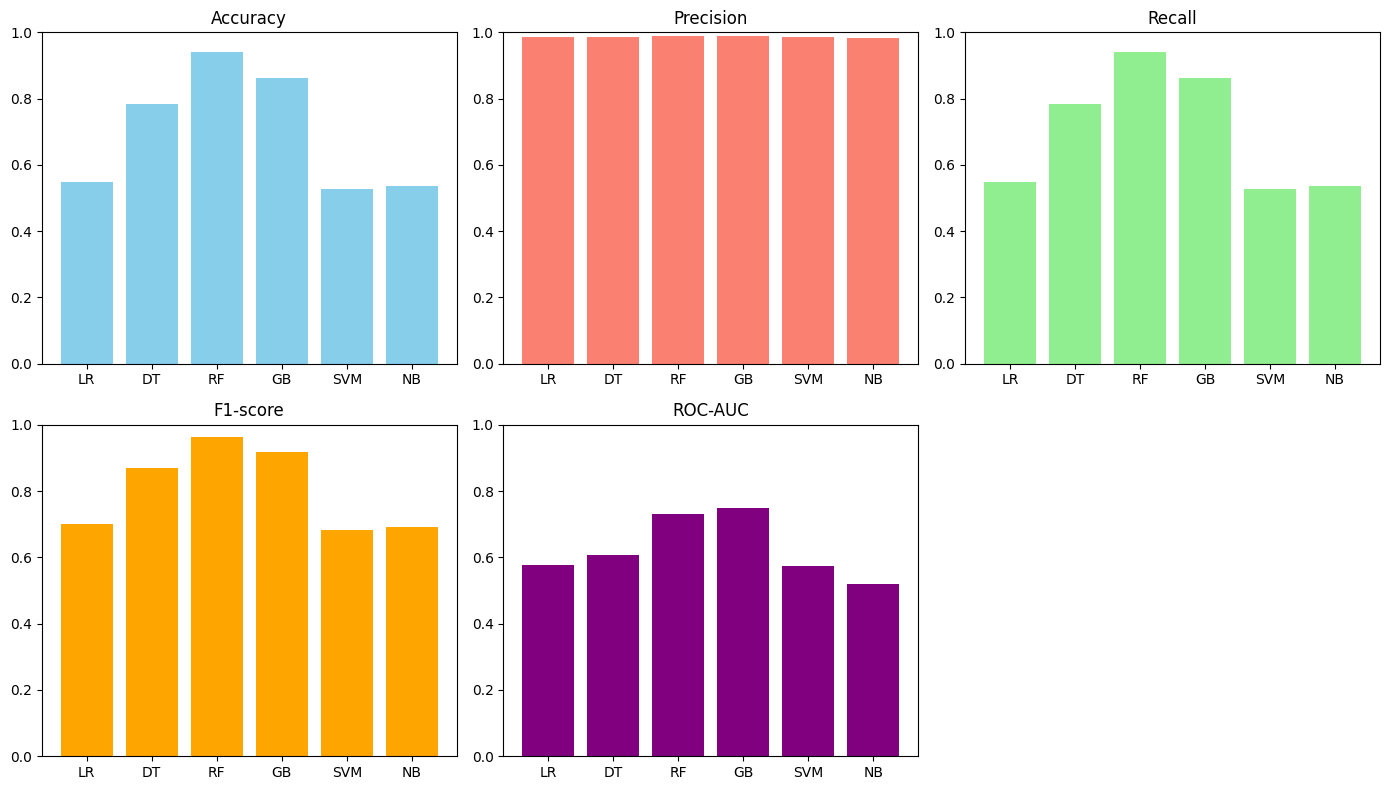

In [52]:
import matplotlib.pyplot as plt
import pandas as pd

# Example: metrics from your PySpark models
# Suppose you have run models and stored metrics in dictionaries
# lr_metrics, dt_metrics, rf_metrics, gb_metrics, svm_metrics, nb_metrics

model_names = ['LR', 'DT', 'RF', 'GB', 'SVM', 'NB']
metrics_list = [lr_metrics_best, dt_metrics_best, rf_metrics_best, gb_metrics_best, svm_metrics_best, nb_metrics_best]

# Convert to pandas DataFrame for plotting
metrics_df = pd.DataFrame(metrics_list, index=model_names)
metrics_df = metrics_df.fillna(0)  # Replace None with 0 for ROC-AUC if needed

# Plotting
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.bar(metrics_df.index, metrics_df['Accuracy'], color='skyblue')
plt.title('Accuracy')
plt.ylim(0, 1)

plt.subplot(2, 3, 2)
plt.bar(metrics_df.index, metrics_df['Precision'], color='salmon')
plt.title('Precision')
plt.ylim(0, 1)

plt.subplot(2, 3, 3)
plt.bar(metrics_df.index, metrics_df['Recall'], color='lightgreen')
plt.title('Recall')
plt.ylim(0, 1)

plt.subplot(2, 3, 4)
plt.bar(metrics_df.index, metrics_df['F1-score'], color='orange')
plt.title('F1-score')
plt.ylim(0, 1)

plt.subplot(2, 3, 5)
plt.bar(metrics_df.index, metrics_df['ROC-AUC'], color='purple')
plt.title('ROC-AUC')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


It can be seen that after optimization, random forest has the best performance.

#### Comparing Before and After Optimization

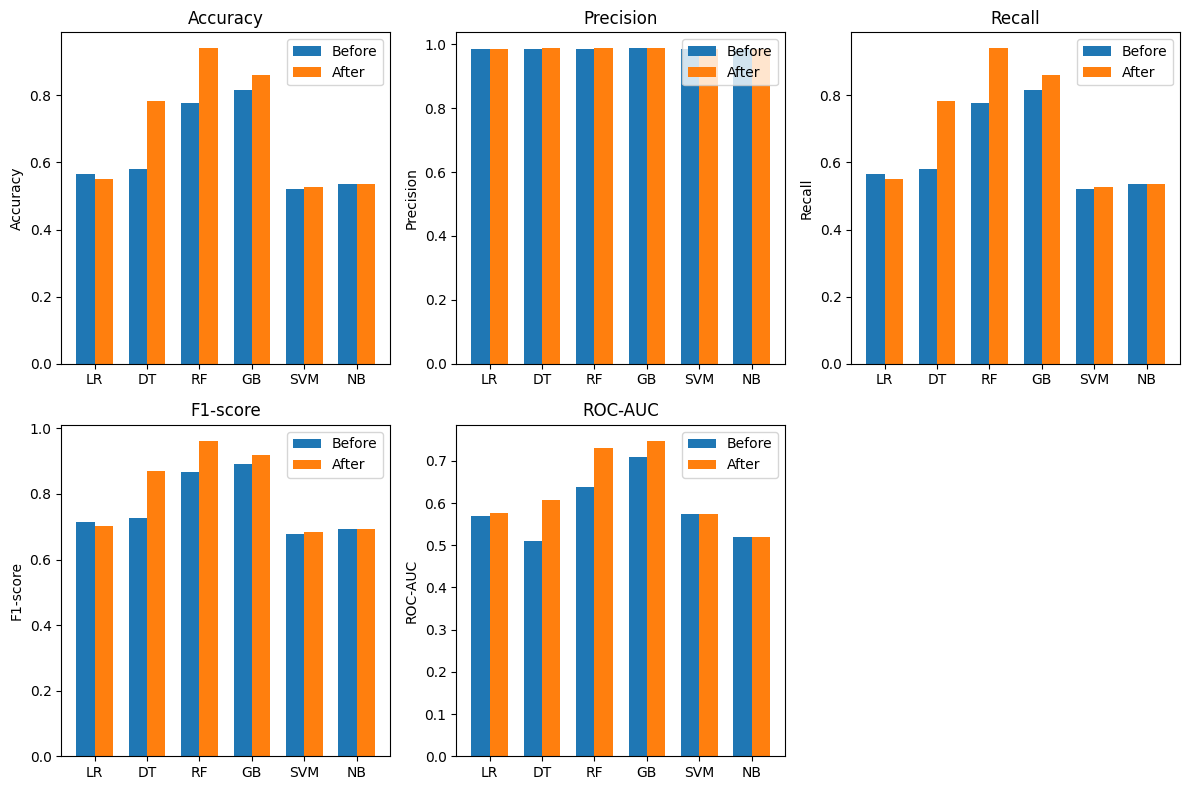

In [53]:
# Define the models and their corresponding metrics before optimization
models = ['LR', 'DT', 'RF', 'GB', 'SVM', 'NB']
metrics_before = {
   'Accuracy' : [lr_metrics['Accuracy'], dt_metrics['Accuracy'], rf_metrics['Accuracy'], gb_metrics['Accuracy'], svm_metrics['Accuracy'], nb_metrics['Accuracy']],
    'Precision' :  [lr_metrics['Precision'], dt_metrics['Precision'], rf_metrics['Precision'], gb_metrics['Precision'], svm_metrics['Precision'], nb_metrics['Precision']],
    'Recall' :  [lr_metrics['Recall'], dt_metrics['Recall'], rf_metrics['Recall'], gb_metrics['Recall'], svm_metrics['Recall'], nb_metrics['Recall']],
    'F1-score' :  [lr_metrics['F1-score'], dt_metrics['F1-score'], rf_metrics['F1-score'], gb_metrics['F1-score'], svm_metrics['F1-score'], nb_metrics['F1-score']],
    'ROC-AUC' : [lr_metrics['ROC-AUC'], dt_metrics['ROC-AUC'], rf_metrics['ROC-AUC'], gb_metrics['ROC-AUC'], svm_metrics['ROC-AUC'], nb_metrics['ROC-AUC']]
}
 

# Define the models and their corresponding metrics after optimization
metrics_after = {
    'Accuracy' : [lr_metrics_best['Accuracy'], dt_metrics_best['Accuracy'], rf_metrics_best['Accuracy'], gb_metrics_best['Accuracy'], svm_metrics_best['Accuracy'], nb_metrics_best['Accuracy']],
    'Precision' :  [lr_metrics_best['Precision'], dt_metrics_best['Precision'], rf_metrics_best['Precision'], gb_metrics_best['Precision'], svm_metrics_best['Precision'], nb_metrics_best['Precision']],
    'Recall' :  [lr_metrics_best['Recall'], dt_metrics_best['Recall'], rf_metrics_best['Recall'], gb_metrics_best['Recall'], svm_metrics_best['Recall'], nb_metrics_best['Recall']],
    'F1-score' :  [lr_metrics_best['F1-score'], dt_metrics_best['F1-score'], rf_metrics_best['F1-score'], gb_metrics_best['F1-score'], svm_metrics_best['F1-score'], nb_metrics_best['F1-score']],
    'ROC-AUC' :  [lr_metrics_best['ROC-AUC'], dt_metrics_best['ROC-AUC'], rf_metrics_best['ROC-AUC'], gb_metrics_best['ROC-AUC'], svm_metrics_best['ROC-AUC'], nb_metrics_best['ROC-AUC']]
}

# Plotting the metrics before and after optimization
fig, axs = plt.subplots(2, 3, figsize=(12, 8))

# Define the bar width
bar_width = 0.35
index = np.arange(len(models))

# Plot each metric separately
for i, metric in enumerate(metrics_before.keys()):
    axs[i//3, i%3].bar(index - bar_width/2, metrics_before[metric], bar_width, label='Before')
    axs[i//3, i%3].bar(index + bar_width/2, metrics_after[metric], bar_width, label='After')
    axs[i//3, i%3].set_title(metric)
    axs[i//3, i%3].set_ylabel(metric)
    axs[i//3, i%3].set_xticks(index)
    axs[i//3, i%3].set_xticklabels(models)
    axs[i//3, i%3].legend()


# turn off unused subplot
axs[1, 2].axis('off')

plt.tight_layout()
plt.show()

This comparision helps to know that Random Forest is the best model for the prediction of our dataset compared with the other model. Even though the value of the metrics for gradient boosting was high, after optimization, the values of metrics for the random forest is higher then gradiant boosting. Thus we choose, Random Forest.